In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

(3867, 3)


Text(0.5, 1.0, 'Detrended Flux vs BJD')

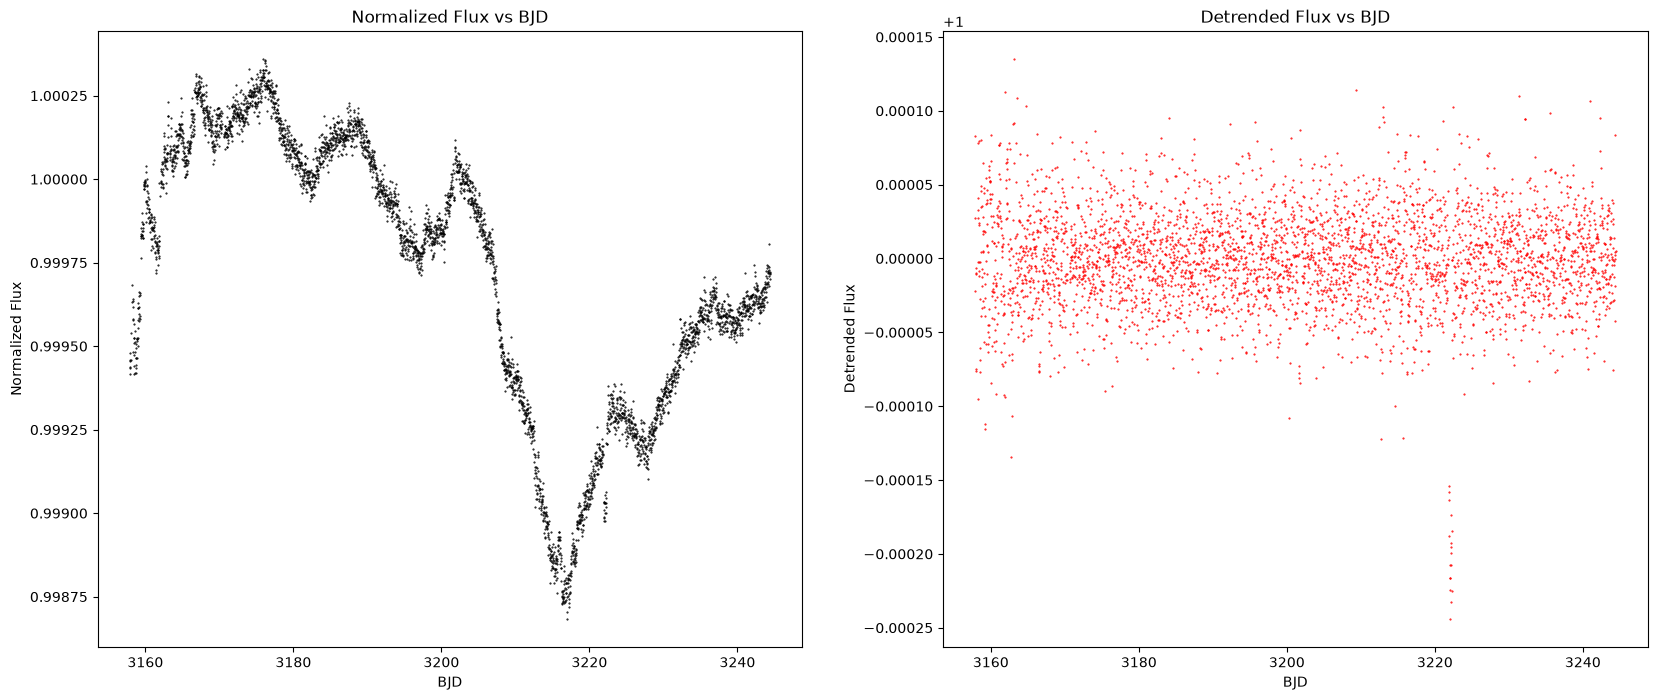

In [3]:
data = np.loadtxt('../data/apjladf06ft3_mrt.txt', skiprows=15)
print(data.shape)
bjd=data[:,0]
flux_normalized=data[:,1]
flux_detrended=data[:,2]

fig = plt.figure(figsize=(20,8))
ax = fig.add_subplot(121)
ax.plot(bjd, flux_normalized, 'k.', markersize=1)
ax.set_xlabel('BJD')
ax.set_ylabel('Normalized Flux')
ax.set_title('Normalized Flux vs BJD')

ax1 =fig.add_subplot(122)
ax1.plot(bjd, flux_detrended, 'r.', markersize=1)
ax1.set_xlabel('BJD')
ax1.set_ylabel('Detrended Flux')
ax1.set_title('Detrended Flux vs BJD') #flux with substracted or devided trend line



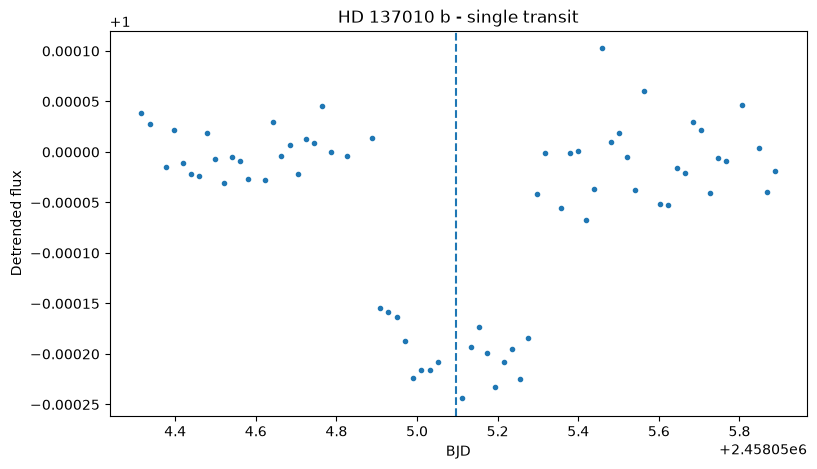

In [4]:
t = data[:, 0] + 2454833
flux = data[:, 2]

t0 = 2458055.0969 #transition mitpoint , approximately october

mask = np.abs(t - t0) < 0.8 # within 0.8 days of the transit, the transit was actually ca. 0.2 days but we want left and right 0.6 days of baseline
#print(mask[2500:3300])

t_transit = t[mask] #makes the array of the transit
flux_transit = flux[mask]

plt.figure(figsize=(9, 5))
plt.plot(t_transit, flux_transit, ".")
plt.axvline(t0, linestyle="--")

plt.xlabel("BJD")
plt.ylabel("Detrended flux")
plt.title("HD 137010 b - single transit")
plt.show()

In [5]:
import batman

In [6]:
params = batman.TransitParams() #object to store transit parameters

params.t0 = t0 #time of inferior conjunction
params.per = 355.0 #orbital period
params.rp = 0.01368 #planet radius (in units of stellar radii)
params.a = 270.0 #semi-major axis (in units of stellar radii)

params.inc = 90.0       # first try: b = 0 orbital inclination (in degrees) (neigung des Orbits)
params.ecc = 0.0    #eccentricity
params.w = 90.0 #longitude of periastron (in degrees)

params.u = [0.56, 0.10] #limb darkening coefficients [u1, u2]
params.limb_dark = "quadratic" #limb darkening model (depnds on the stellar intensity profile, which is a function of the stellar atmosphere and the wavelength of observation)

model = batman.TransitModel(
    params,
    t_transit,
    supersample_factor=10, #this is the number of points to calculate in each exposure time, which is then averaged to get the final flux value for that exposure
    exp_time=29.4 / (24 * 60) #exposure time in days (29.4 minutes for Kepler long cadence data)
)

model_flux = model.light_curve(params)

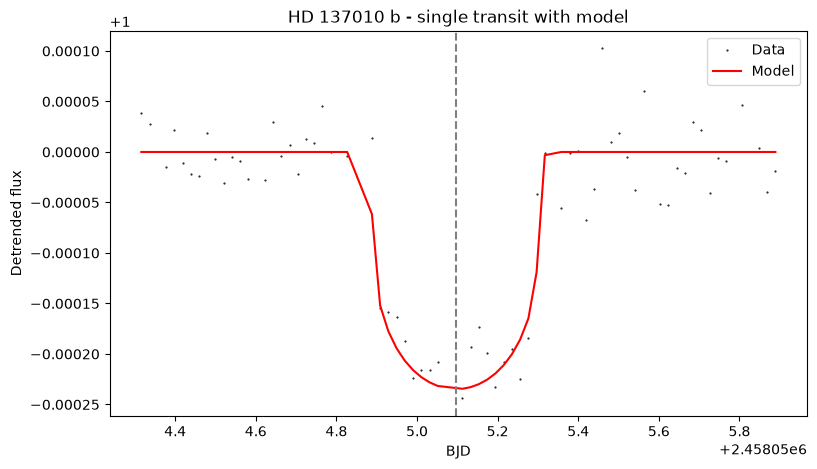

In [7]:
fig = plt.figure(figsize=(9, 5))
plt.plot(t_transit, flux_transit, "k.", markersize=1, label="Data")
plt.plot(t_transit, model_flux, "r-", label="Model")
plt.axvline(t0, linestyle="--", color="gray")
plt.xlabel("BJD")
plt.ylabel("Detrended flux")
plt.title("HD 137010 b - single transit with model")
plt.legend()

MCMC Algrythm and Parameters Estimation

In [8]:
import numpy as np
import batman
import emcee

def run_mcmc(t, flux, t0_guess, nwalkers=50, nsteps=5000):
    # Noise estimate from out-of-transit data (transit is ~0.41 d long)
    oot = np.abs(t - t0_guess) > 0.4
    sigma = np.std(flux[oot])

    # batman setup, built once
    params = batman.TransitParams()
    params.t0 = t0_guess
    params.per = 355.0          # fixed; degenerate with a for a single transit
    params.rp = 0.015
    params.a = 270.0
    params.inc = 89.9
    params.ecc = 0.0
    params.w = 90.0
    params.limb_dark = "quadratic"
    params.u = [0.5, 0.2]       # replace with values for a K3.5 V star
    m = batman.TransitModel(params, t)

    def log_prior(theta):
        t0, rp, a, inc = theta
        if not (t0_guess - 0.2 < t0 < t0_guess + 0.2): return -np.inf
        if not (0.0 < rp < 0.1):                        return -np.inf
        if not (10.0 < a < 2000.0):                     return -np.inf
        if not (80.0 < inc <= 90.0):                    return -np.inf
        return 0.0              # uniform priors

    def log_likelihood(theta):
        params.t0, params.rp, params.a, params.inc = theta
        model = m.light_curve(params)
        return -0.5 * np.sum(((flux - model) / sigma) ** 2)

    def log_probability(theta):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        return lp + log_likelihood(theta)

    theta0 = np.array([t0_guess, 0.015, 270.0, 89.9])
    ndim = len(theta0)
    scale = np.array([1e-3, 1e-4, 1.0, 0.01])
    p0 = theta0 + scale * np.random.randn(nwalkers, ndim) #one needs 50 priors of every entry in the theta0 array, so we create a 50x4 array of random values around the initial guess
    p0[:, 3] = np.minimum(p0[:, 3], 90.0)   # keep inc within the prior

    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability)
    sampler.run_mcmc(p0, nsteps, progress=True)
    return sampler

sampler = run_mcmc(t_transit, flux_transit, t0)


You must install the tqdm library to use progress indicators with emcee


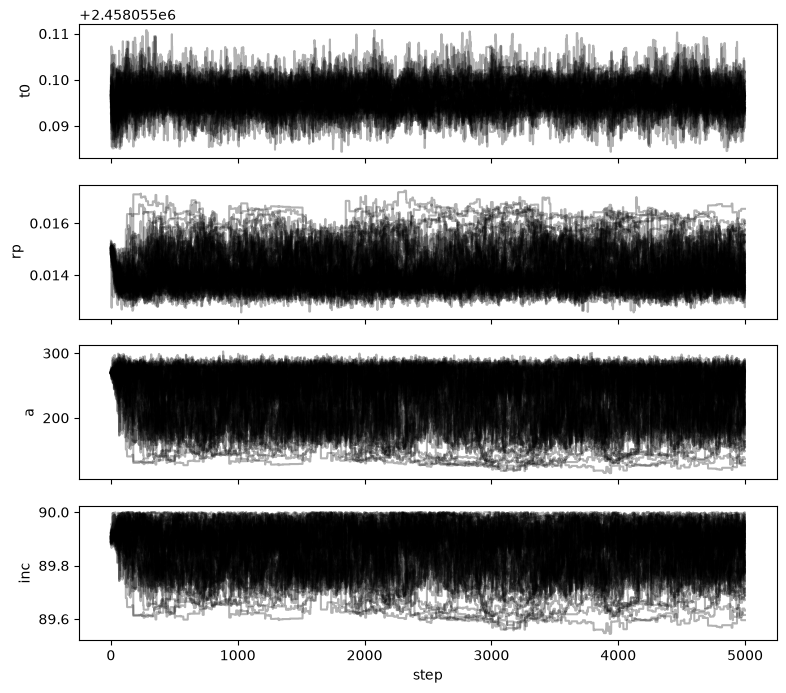

In [9]:
print(sampler)
import matplotlib.pyplot as plt
import pandas as pd

labels = ["t0", "rp", "a", "inc"]
chain = sampler.get_chain()          # shape (nsteps, nwalkers, ndim)

fig, axes = plt.subplots(len(labels), 1, figsize=(9, 8), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(chain[:, :, i], "k", alpha=0.3)
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel("step")
plt.show()

df = pd.DataFrame(chain.reshape(-1, len(labels)), columns=labels)
df.to_csv("ecc_to_0_fix_mcmc_chain.csv", index=False)  # Save the chain to a CSV file for later analysis

[ 86.40431856 186.45349544 187.61086074 194.03707188]
t0 = 2458055.096305 +0.002977 -0.002754
rp = 0.014094 +0.001309 -0.000618
a = 235.255403 +41.353503 -69.109606
inc = 89.864165 +0.097968 -0.144010


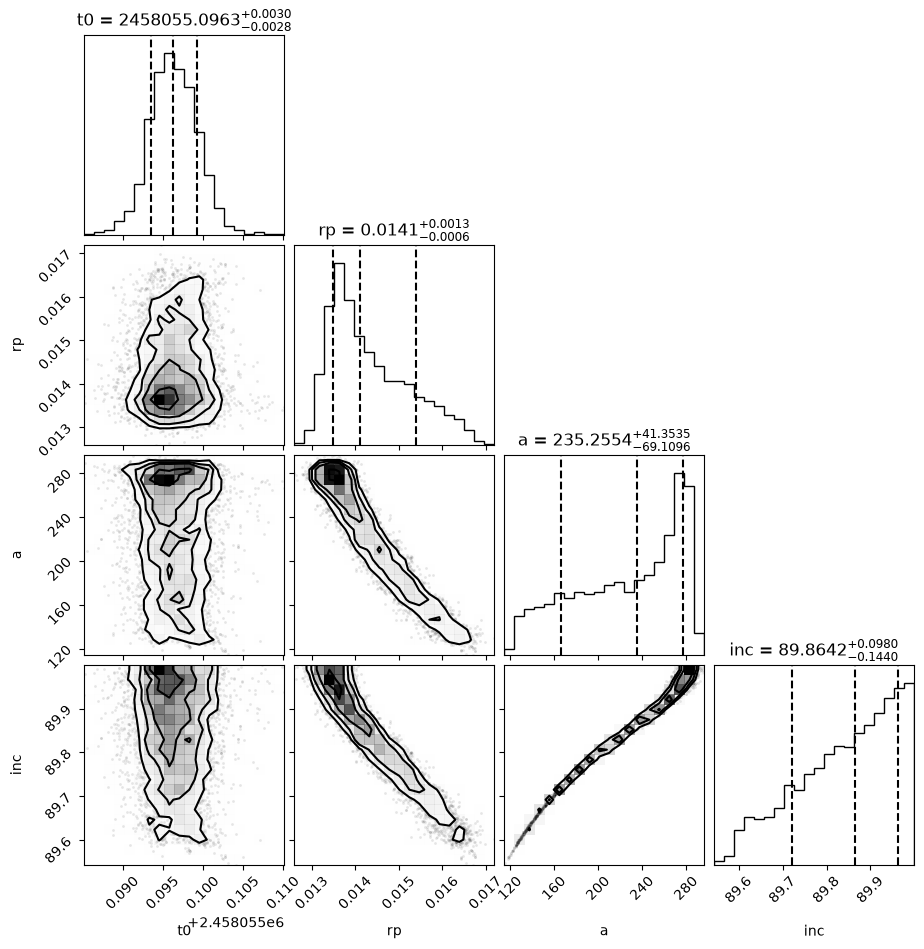

In [10]:
tau = sampler.get_autocorr_time(tol=0)
print(tau)

burn = int(3 * np.max(tau))
thin = max(1, int(0.5 * np.min(tau)))
flat = sampler.get_chain(discard=burn, thin=thin, flat=True)   # shape (N, ndim)

for i, name in enumerate(labels):                           #68% interval
    q16, q50, q84 = np.percentile(flat[:, i], [16, 50, 84])
    print(f"{name} = {q50:.6f} +{q84 - q50:.6f} -{q50 - q16:.6f}")

import corner   # pip install corner

fig = corner.corner(flat, labels=labels, quantiles=[0.16, 0.5, 0.84], #roundish dhape corresponds to non correlation while banana shape means strongly correlated parameters
                    show_titles=True, title_fmt=".4f")
plt.show()

t0 is clean. The histogram is a nice symmetric bell. Its posterior is $2458055.0963^{+0.0030}_{-0.0027}$, which agrees with the paper’s $2458055.0969$ well within the error bars. In the first column, all the blobs are upright and round, so $t_0$ isn’t correlated with anything. The data pin down the timing independently of the shape of the transit.

a and inc are strongly degenerate. Their joint panel isn’t a blob but a thin curved line. That’s the relation from before,

$$b = a \cos i,$$

and each point on the curve gives a transit of the same duration. Both 1D histograms pile up against a hard wall:

inc against 90°, which is the prior limit.
a against about 285, the physical limit for $b = 0$ with the period fixed.

Because of these walls, the distributions are lopsided, and the median isn’t a good summary. The median of $a = 244$ lies well below the most likely value of about 280. For parameters like these, it’s better to quote the peak and a one-sided limit. The paper does this too: $b < 0.85$ and $i > 89.82^\circ$ at $3\sigma$.

rp is anticorrelated with a and inc. In the rp–a and rp–inc panels, the cloud runs diagonally downwards. Large $r_p$ goes together with small $a$ and smaller $i$, which is the near-limb transit from before. Near the edge, the star is dimmer because of limb darkening. So to block the same amount of light and reproduce the observed depth of about 225 ppm, the planet has to be bigger. That creates the long tail of rp up to 0.016–0.017 and makes its histogram skewed to the right.

Comparison with the paper. Your $r_p = 0.0140^{+0.0012}_{-0.0005}$ matches their $0.01368^{+0.0006}_{-0.0004}$ well. Your upper tail is a bit longer, probably because you don’t use the stellar density prior that the paper uses. You also can’t compare $a$ directly: you fixed $P = 355$ d, while they let the period vary. Their $a/R_* = 270^{+93}_{-37}$ reaches much higher values than your hard wall at about 285 allows.

In short: the timing is measured cleanly. The planet’s size is measured well, apart from a tail towards larger values. The orbit geometry ($a$, $i$, and therefore $b$) is degenerate: one transit can’t tell a central crossing of a distant orbit apart from an off-centre crossing of a closer one. That degeneracy is the core of your project, and it gets larger once the period and eccentricity are also free.


In [11]:
import numpy as np
import batman
import emcee

def run_mcmc(t, flux, t0_guess, nwalkers=50, nsteps=50000):
    oot = np.abs(t - t0_guess) > 0.4
    sigma = np.std(flux[oot])

    params = batman.TransitParams()
    params.t0 = t0_guess
    params.per = 355.0
    params.rp = 0.0137
    params.a = 270.0
    params.inc = 89.9
    params.ecc = 0.0
    params.w = 90.0
    params.limb_dark = "quadratic"
    params.u = [0.60, 0.12]            # Claret 2018 values used in the paper
    m = batman.TransitModel(params, t)

    def unpack(theta):
        t0, rp, a, inc, h, k = theta   # h = sqrt(e) cos w, k = sqrt(e) sin w, this is the best way to sample it such that sampler can jump to neigbouring points without getting stuck in the e ~ 0 region
        e = h**2 + k**2
        w = np.degrees(np.arctan2(k, h)) % 360.0
        return t0, rp, a, inc, e, w

    def log_prior(theta):
        t0, rp, a, inc, e, w = unpack(theta)
        if not (t0_guess - 0.2 < t0 < t0_guess + 0.2): return -np.inf
        if not (0.0 < rp < 0.1):                        return -np.inf
        if not (10.0 < a < 2000.0):                     return -np.inf
        if not (80.0 < inc <= 90.0):                    return -np.inf
        if not (0.0 <= e < 0.9):                        return -np.inf  # avoid e -> 1
        if a * (1.0 - e) < 1.0 + rp:                    return -np.inf  # no orbit through the star
        return 0.0       # flat in (h, k)  =  e ~ U(0, 0.9), w ~ U(0, 360)

    def log_likelihood(theta):
        t0, rp, a, inc, e, w = unpack(theta)
        params.t0, params.rp, params.a, params.inc = t0, rp, a, inc
        params.ecc, params.w = e, w
        try:
            model = m.light_curve(params)
        except RuntimeError:           # Kepler solver failed: treat as impossible
            return -np.inf
        return -0.5 * np.sum(((flux - model) / sigma) ** 2)

    def log_probability(theta):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        ll = log_likelihood(theta)
        return lp + ll if np.isfinite(ll) else -np.inf

    # Start every walker at a valid position
    theta0 = np.array([t0_guess, 0.0137, 270.0, 89.9, 0.05, 0.05])
    ndim = len(theta0)
    scale = np.array([1e-3, 1e-4, 1.0, 0.01, 0.02, 0.02])
    p0 = []
    while len(p0) < nwalkers:
        trial = theta0 + scale * np.random.randn(ndim)
        if np.isfinite(log_probability(trial)):
            p0.append(trial)
    p0 = np.array(p0)

    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability)
    sampler.run_mcmc(p0, nsteps, progress=True)
    return sampler

sampler = run_mcmc(t_transit, flux_transit, t0)

You must install the tqdm library to use progress indicators with emcee


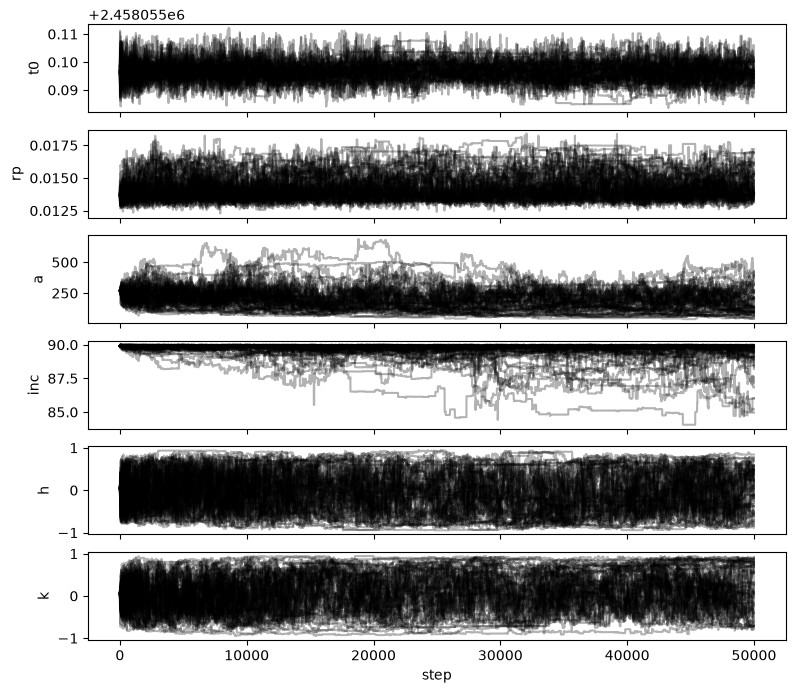

In [12]:
print(sampler)
import matplotlib.pyplot as plt

labels = ["t0", "rp", "a", "inc", "h", "k"]
chain = sampler.get_chain()          # shape (nsteps, nwalkers, ndim)

fig, axes = plt.subplots(len(labels), 1, figsize=(9, 8), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(chain[:, :, i], "k", alpha=0.3)
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel("step")
plt.show()

df = pd.DataFrame(chain.reshape(-1, len(labels)), columns=labels)
df.to_csv("ecc_varry_mcmc_chain.csv", index=False)  # Save the chain to a CSV file for later analysis

[1894.97147456 2492.69643284 3627.44500846 3770.07051936 3361.37544573
 3509.08066757]
t0 = 2458055.096327 +0.003327 -0.002986
rp = 0.014202 +0.001531 -0.000795
a = 160.040524 +104.257785 -68.362784
inc = 89.716443 +0.209678 -0.753238
h = -0.098609 +0.655941 -0.560049
k = 0.212757 +0.507803 -0.648730


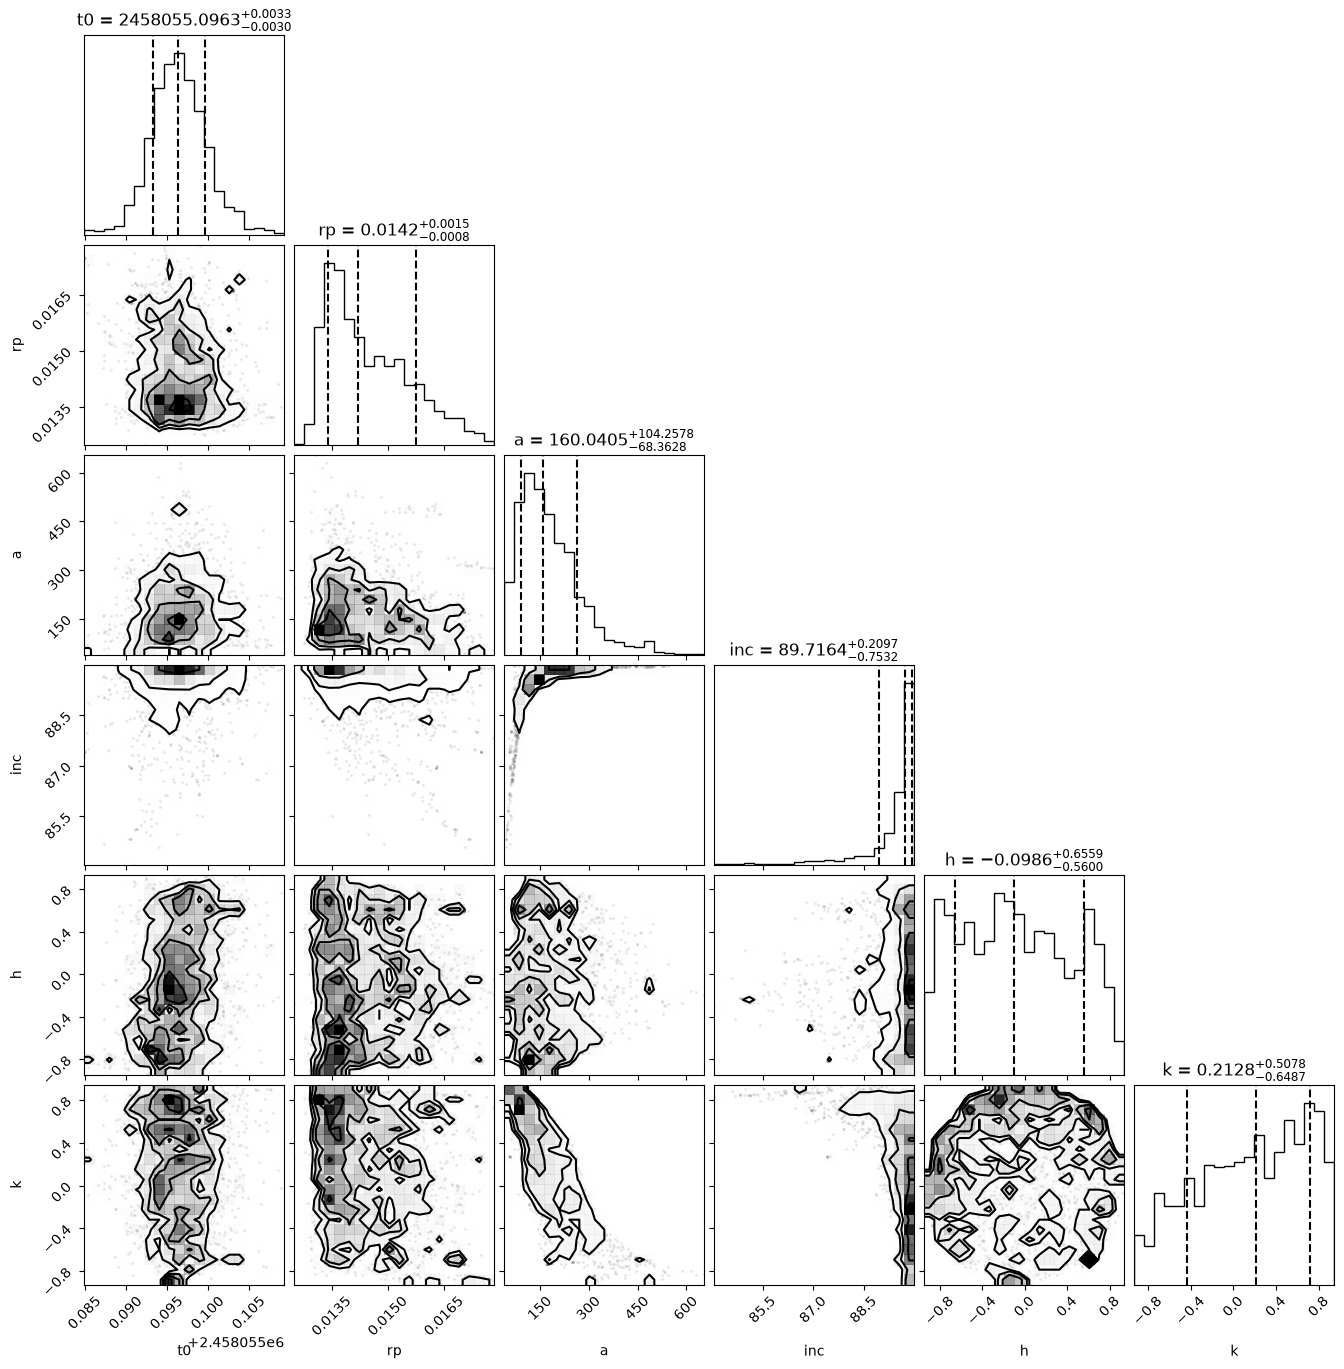

In [13]:
tau = sampler.get_autocorr_time(tol=0)
print(tau)

burn = int(3 * np.max(tau))
thin = max(1, int(0.5 * np.min(tau)))
flat = sampler.get_chain(discard=burn, thin=thin, flat=True)   # shape (N, ndim)

for i, name in enumerate(labels):                           #68% interval
    q16, q50, q84 = np.percentile(flat[:, i], [16, 50, 84])
    print(f"{name} = {q50:.6f} +{q84 - q50:.6f} -{q50 - q16:.6f}")

import corner   # pip install corner

fig = corner.corner(flat, labels=labels, quantiles=[0.16, 0.5, 0.84], #roundish dhape corresponds to non correlation while banana shape means strongly correlated parameters
                    show_titles=True, title_fmt=".4f")
plt.show()

You must install the tqdm library to use progress indicators with emcee
/tmp/ipykernel_7187/3795124970.py:14: RuntimeWarning: invalid value encountered in scalar power
  return (G * rho * 1000.0 * (P * DAY) ** 2 / (3.0 * np.pi)) ** (1.0 / 3.0)


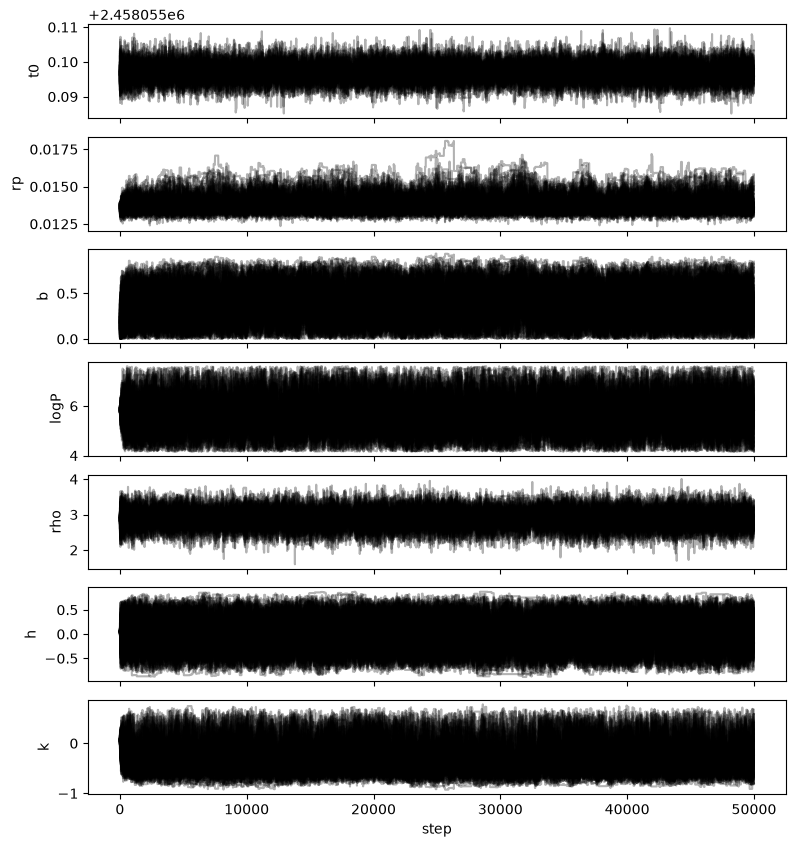

tau: [236.49374818 476.17742096 377.99575452 379.88098219 214.3013495
 343.75069041 355.50890054]
N / tau_max = 105.00287875677596 (want > 50)
acceptance = 0.0492
t0       = 2458055.097065 +0.002537 -0.002525
rp       = 0.013757 +0.000901 -0.000424
b        = 0.414429 +0.273498 -0.274134
P [d]    = 286.150706 +392.156454 -171.569005
a/R*     = 231.109676 +181.877231 -105.328098
rho      = 2.889982 +0.249647 -0.250098
e        = 0.373999 +0.268470 -0.256769
w [deg]  = 247.686458 +64.023141 -108.325481


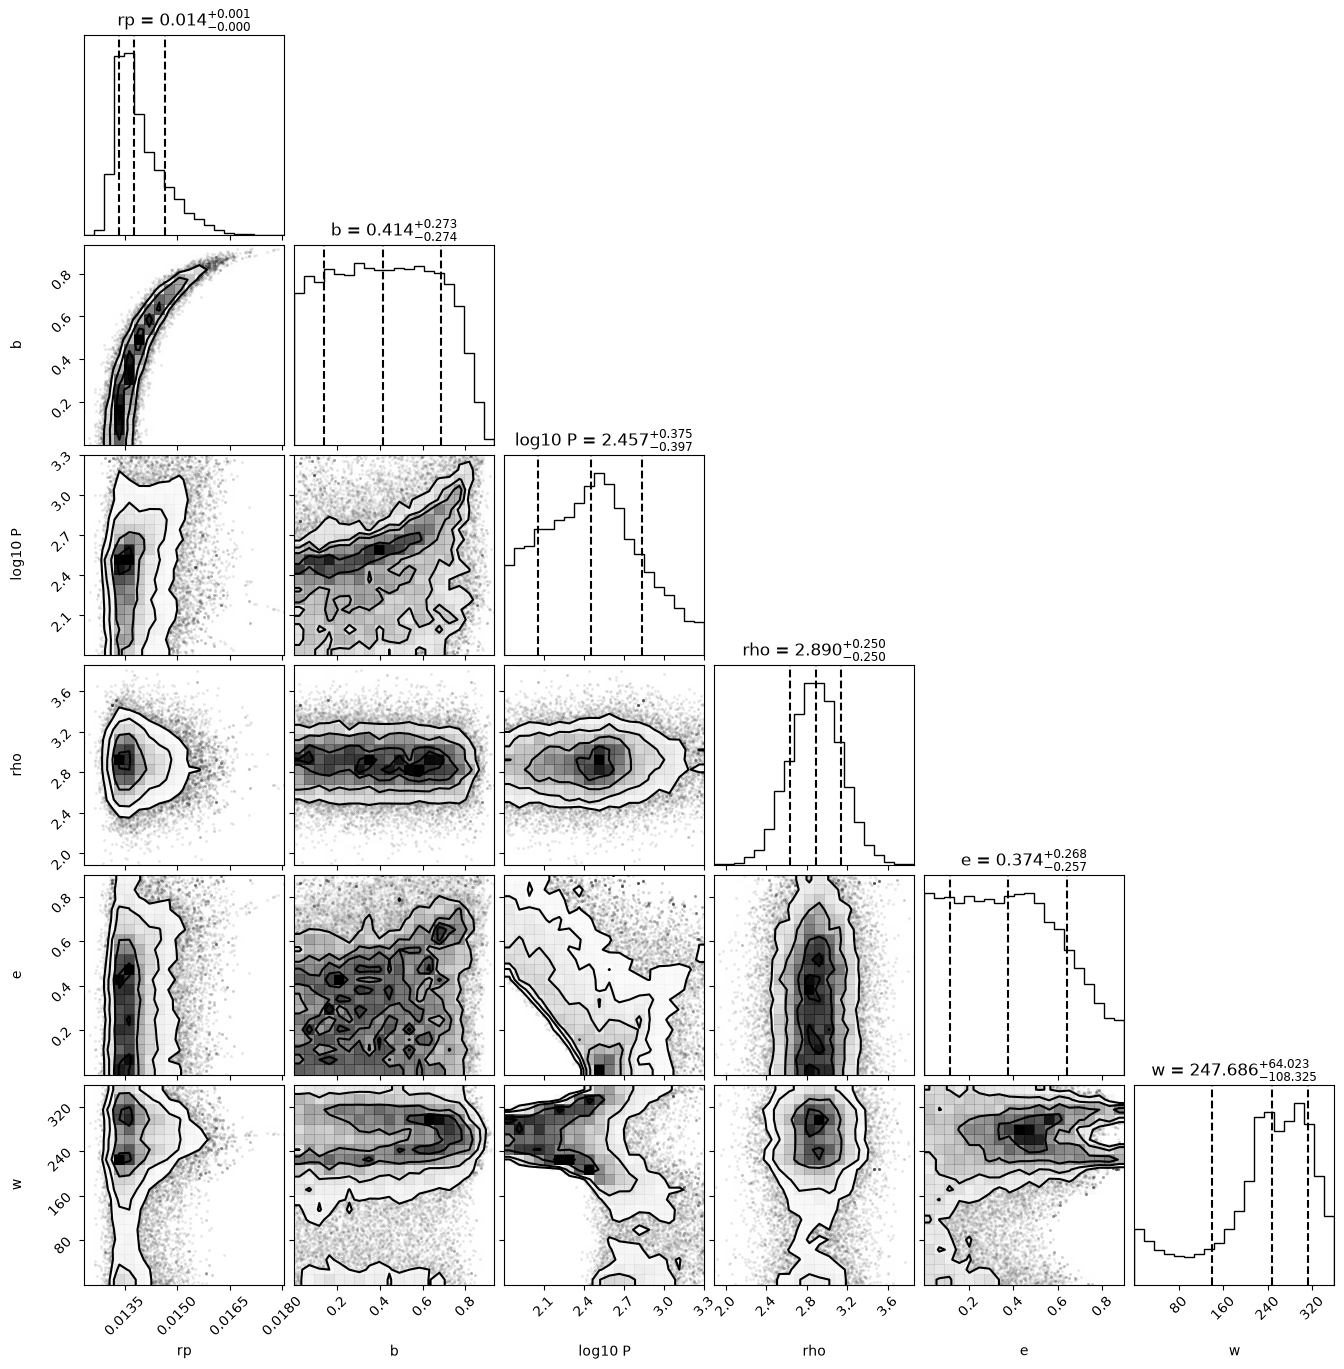

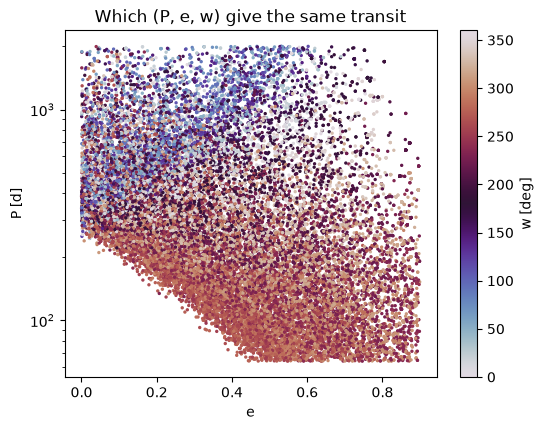

In [14]:
import numpy as np
import batman
import emcee
import matplotlib.pyplot as plt
import corner

G = 6.674e-11                 # m^3 kg^-1 s^-2
DAY = 86400.0
RHO_STAR, RHO_ERR = 2.90, 0.28       # g/cm^3, Venner et al. 2026
P_MIN, P_MAX = 64.0, 2000.0          # days; no second transit in K2 C15, P < 2000 d as in the paper

def a_from_density(P, rho):
    """Kepler's third law: a/R* from period [d] and stellar density [g/cm^3]."""
    return (G * rho * 1000.0 * (P * DAY) ** 2 / (3.0 * np.pi)) ** (1.0 / 3.0)

def run_mcmc(t, flux, t0_guess, nwalkers=50, nsteps=50000):
    oot = np.abs(t - t0_guess) > 0.4
    sigma = np.std(flux[oot])

    params = batman.TransitParams()
    params.t0 = t0_guess
    params.per = 355.0
    params.rp = 0.0137
    params.a = 270.0
    params.inc = 89.9
    params.ecc = 0.0
    params.w = 90.0
    params.limb_dark = "quadratic"
    params.u = [0.60, 0.12]            # Claret 2018 values used in the paper
    # K2 long cadence: each point is a 29.4 min average, so supersample the model
    m = batman.TransitModel(params, t, supersample_factor=10, exp_time=29.4 / 60 / 24)

    def unpack(theta):
        # a is no longer sampled: it follows from P and rho via Kepler's law.
        # b is sampled instead of inc, which removes the a-inc banana.
        t0, rp, b, logP, rho, h, k = theta   # h = sqrt(e) cos w, k = sqrt(e) sin w
        P = np.exp(logP)
        e = h**2 + k**2
        w = np.degrees(np.arctan2(k, h)) % 360.0
        a = a_from_density(P, rho)
        # impact parameter for an eccentric orbit (Winn 2010)
        cosi = b * (1.0 + e * np.sin(np.radians(w))) / (a * (1.0 - e**2))
        inc = np.degrees(np.arccos(cosi)) if 0.0 <= cosi < 1.0 else np.nan
        return t0, rp, b, P, rho, e, w, a, inc

    def log_prior(theta):
        t0, rp, b, P, rho, e, w, a, inc = unpack(theta)
        if not (t0_guess - 0.2 < t0 < t0_guess + 0.2): return -np.inf
        if not (0.0 < rp < 0.1):                        return -np.inf
        if not (0.0 <= b < 1.0 + rp):                   return -np.inf
        if not (P_MIN < P < P_MAX):                     return -np.inf
        if not (0.5 < rho < 10.0):                      return -np.inf
        if not (0.0 <= e < 0.9):                        return -np.inf  # avoid e -> 1
        if a * (1.0 - e) < 1.0 + rp:                    return -np.inf  # no orbit through the star
        if np.isnan(inc):                               return -np.inf

        lp = 0.0
        lp += -5.0 / 3.0 * np.log(P) + np.log(P)     # p(P) ~ P^(-5/3) (Kipping 2018); +log P = Jacobian for sampling log P
        lp += -0.5 * ((rho - RHO_STAR) / RHO_ERR)**2  # stellar density from spectroscopy/isochrones
        return lp       # flat in (h, k)  =  e ~ U(0, 0.9), w ~ U(0, 360)

    def log_likelihood(theta):
        t0, rp, b, P, rho, e, w, a, inc = unpack(theta)
        params.t0, params.rp, params.per, params.a, params.inc = t0, rp, P, a, inc
        params.ecc, params.w = e, w
        try:
            model = m.light_curve(params)
        except RuntimeError:           # Kepler solver failed: treat as impossible
            return -np.inf
        return -0.5 * np.sum(((flux - model) / sigma) ** 2)

    def log_probability(theta):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        ll = log_likelihood(theta)
        return lp + ll if np.isfinite(ll) else -np.inf

    # Start every walker at a valid position
    theta0 = np.array([t0_guess, 0.0137, 0.2, np.log(355.0), RHO_STAR, 0.05, 0.05]) #t0, rp, b, logP, rho, h, k
    ndim = len(theta0)
    scale = np.array([1e-3, 1e-4, 0.05, 0.05, 0.05, 0.02, 0.02])
    p0 = []
    while len(p0) < nwalkers:
        trial = theta0 + scale * np.random.randn(ndim)
        if np.isfinite(log_probability(trial)):
            p0.append(trial)
    p0 = np.array(p0)

    # Differential-evolution moves handle the curved P-e-w degeneracy better
    # than the default stretch move (expect a low acceptance fraction, ~0.1)
    moves = [(emcee.moves.DEMove(), 0.8), (emcee.moves.DESnookerMove(), 0.2)]
    sampler = emcee.EnsembleSampler(nwalkers, ndim, log_probability, moves=moves)
    sampler.run_mcmc(p0, nsteps, progress=True)
    return sampler

sampler = run_mcmc(t_transit, flux_transit, t0)

# ---------------------------------------------------------------- trace plots
labels = ["t0", "rp", "b", "logP", "rho", "h", "k"]
chain = sampler.get_chain()          # shape (nsteps, nwalkers, ndim)

fig, axes = plt.subplots(len(labels), 1, figsize=(9, 10), sharex=True)
for i, ax in enumerate(axes):
    ax.plot(chain[:, :, i], "k", alpha=0.3)
    ax.set_ylabel(labels[i])
axes[-1].set_xlabel("step")
plt.show()


df = pd.DataFrame(chain.reshape(-1, len(labels)), columns=labels)
df.to_csv("ecc_varry_a_fix_mcmc_chain.csv", index=False)  # Save the chain to a CSV file for later analysis

# ---------------------------------------------------------------- convergence
tau = sampler.get_autocorr_time(tol=0)
print("tau:", tau)
print("N / tau_max =", chain.shape[0] / np.max(tau), "(want > 50)")
print("acceptance =", np.mean(sampler.acceptance_fraction))

burn = int(3 * np.max(tau))
thin = max(1, int(0.5 * np.min(tau)))
flat = sampler.get_chain(discard=burn, thin=thin, flat=True)   # shape (N, ndim)

# ---------------------------------------------------------------- derived quantities
t0_s, rp_s, b_s, logP_s, rho_s, h_s, k_s = flat.T
P_s = np.exp(logP_s)
e_s = h_s**2 + k_s**2
w_s = np.degrees(np.arctan2(k_s, h_s)) % 360
a_s = a_from_density(P_s, rho_s)

derived = {"t0": t0_s, "rp": rp_s, "b": b_s, "P [d]": P_s, "a/R*": a_s,
           "rho": rho_s, "e": e_s, "w [deg]": w_s}

for name, x in derived.items():                           # 68% intervals
    q16, q50, q84 = np.percentile(x, [16, 50, 84])
    print(f"{name:8s} = {q50:.6f} +{q84 - q50:.6f} -{q50 - q16:.6f}")

# ---------------------------------------------------------------- corner plot
# roundish shape = no correlation, banana shape = strongly correlated parameters
plot_data = np.column_stack([rp_s, b_s, np.log10(P_s), rho_s, e_s, w_s])

plot_labels = ["rp", "b", "log10 P", "rho", "e", "w"]
fig = corner.corner(plot_data, labels=plot_labels, quantiles=[0.16, 0.5, 0.84],
                    show_titles=True, title_fmt=".3f")
plt.show()
    
# ---------------------------------------------------------------- the key degeneracy
plt.figure(figsize=(6, 4.5))
sc = plt.scatter(e_s, P_s, c=w_s, s=2, cmap="twilight", vmin=0, vmax=360)
plt.yscale("log")
plt.xlabel("e"); plt.ylabel("P [d]")
plt.colorbar(sc, label="w [deg]")
plt.title("Which (P, e, w) give the same transit")
plt.show() 